# Rewarded-UA account review: finding the revenue levers

This report shows how a growth manager reviews five ad accounts on a Monday morning. It highlights which accounts bring in the most results, which ones hit their ROAS targets, where money is being wasted, why revenue dropped, how much profit each section makes, and how much money each fix can save.

**How this project was made**: I built it using Claude (AI) to learn and demonstrate how rewarded user acquisition works (including key concepts like ROAS, ad caps, user cohorts, retention, and profit margins). The data is fake (from Aug 1 – Sep 29, 2026), created to practice solving real-world growth manager problems using SQL on DuckDB.

In [1]:
%pip install -q duckdb
import os
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

# In Colab, ask for the two CSV files if they are not uploaded yet
try:
    from google.colab import files
    if not (os.path.exists("daily_performance.csv") and os.path.exists("roas_targets.csv")):
        files.upload()   # select both CSV files
except ImportError:
    pass                 # running outside Colab: files are read from the current folder

daily = pd.read_csv("daily_performance.csv", parse_dates=["date"])
targets = pd.read_csv("roas_targets.csv")

def q(sql):
    """Run SQL against the dataframes above and return a table."""
    return duckdb.sql(sql).df()

pd.set_option("display.max_rows", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Saving roas_targets.csv to roas_targets.csv
Saving daily_performance.csv to daily_performance.csv


## 0. What's in the data?

In [2]:
r0 = q("""
--      COUNT(column) only counts rows where that column is NOT empty.
-- Why it matters: D7 metrics need 7 days to "mature". The newest
-- cohorts have no D7 data yet, so we must exclude them later.
SELECT
    COUNT(*)                         AS total_rows,
    MIN(date)                        AS first_day,
    MAX(date)                        AS last_day,
    COUNT(revenue_d7_eur)            AS rows_with_d7_data,
    MAX(CASE WHEN revenue_d7_eur IS NOT NULL THEN date END) AS last_mature_day
FROM daily
""")
r0

,total_rows,first_day,last_day,rows_with_d7_data,last_mature_day
0,1020,2026-08-01,2026-09-29,901,2026-09-22


**Takeaway:** We have data for 1, 020 users from Aug 1 to Sep 29. Since Day 7 results are only available up to Sep 22 (newer users haven't reached 7 days yet), all ROAS numbers below only use completed 7-day data.

## 1. Which accounts are load-bearing?

In [3]:
r1 = q("""
-- Q1. Which accounts are load-bearing?
-- NEW: GROUP BY collapses rows into one row per advertiser.
--      SUM(...) OVER () is a "window function": it adds up the whole
--      column without collapsing rows, so we can compute each share.
SELECT
    advertiser,
    vertical,
    ROUND(SUM(spend_eur))                                        AS spend_eur,
    ROUND(100 * SUM(spend_eur) / SUM(SUM(spend_eur)) OVER (), 1) AS share_of_spend_pct
FROM daily
GROUP BY advertiser, vertical
ORDER BY spend_eur DESC
""")
r1

,advertiser,vertical,spend_eur,share_of_spend_pct
0,Emberfall Legends,Gaming,3000403.0,53.4
1,Tidepool Puzzle,Gaming,1069852.0,19.0
2,Coinmoth,Non-gaming,687010.0,12.2
3,Stackrush Arena,Gaming,561445.0,10.0
4,Stridely Fit,Non-gaming,298743.0,5.3


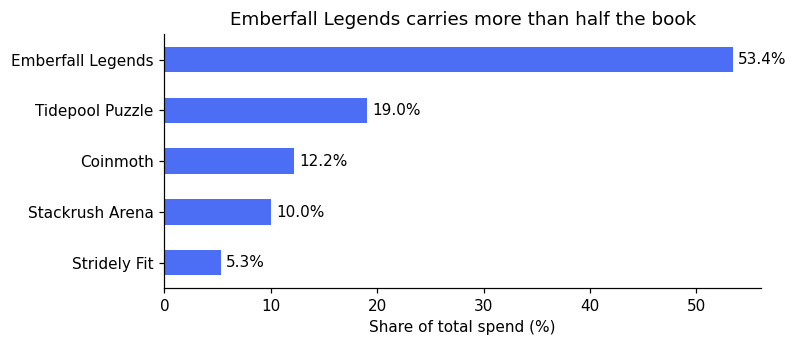

In [4]:
ax = r1.sort_values("share_of_spend_pct").plot.barh(x="advertiser", y="share_of_spend_pct", legend=False,
                                                    color="#4C6EF5", figsize=(7, 3))
ax.set_xlabel("Share of total spend (%)"); ax.set_ylabel("")
ax.set_title("Emberfall Legends carries more than half the book")
for p in ax.patches:
    ax.annotate(f"{p.get_width():.1f}%", (p.get_width() + 0.5, p.get_y() + p.get_height() / 2), va="center")
plt.show()

**Takeaway:** Emberfall Legends accounts for 53.4% ​​of our budget, which is more than all four other accounts combined. Since any change here affects the whole business, we check it first every single day.

## 2. Is each segment hitting its ROAS target?

In [5]:
r2 = q("""
-- Q2. Is each segment hitting the advertiser's ROAS target?
-- NEW: JOIN pulls the target from the second table by matching on
--      advertiser. WHERE ... IS NOT NULL keeps only mature cohorts.
--      CASE WHEN works like an IF statement.
-- D7 ROAS = revenue the users generated in their first 7 days / spend.
SELECT
    d.advertiser,
    d.geo,
    d.os,
    ROUND(SUM(d.spend_eur))                              AS spend_eur,
    ROUND(SUM(d.revenue_d7_eur) / SUM(d.spend_eur), 3)   AS d7_roas,
    t.roas_target_d7,
    ROUND(SUM(d.revenue_d7_eur) / SUM(d.spend_eur) / t.roas_target_d7 - 1, 3) AS vs_target,
    CASE
        WHEN SUM(d.revenue_d7_eur) / SUM(d.spend_eur) < 0.9 * t.roas_target_d7 THEN 'Below target'
        WHEN SUM(d.revenue_d7_eur) / SUM(d.spend_eur) > 1.2 * t.roas_target_d7 THEN 'Headroom'
        ELSE 'On target'
    END AS status
FROM daily AS d
JOIN targets AS t ON d.advertiser = t.advertiser
WHERE d.revenue_d7_eur IS NOT NULL
GROUP BY d.advertiser, d.geo, d.os, t.roas_target_d7
ORDER BY vs_target
""")
r2

,advertiser,geo,os,spend_eur,d7_roas,roas_target_d7,vs_target,status
0,Coinmoth,FR,iOS,130811.0,0.109,0.18,-0.394,Below target
1,Stackrush Arena,BR,Android,154216.0,0.168,0.18,-0.067,On target
2,Emberfall Legends,BR,Android,130310.0,0.192,0.20,-0.039,On target
3,Stridely Fit,UK,iOS,70445.0,0.149,0.15,-0.009,On target
4,Stackrush Arena,FR,Android,86386.0,0.183,0.18,0.016,On target
5,Emberfall Legends,UK,iOS,297310.0,0.205,0.20,0.027,On target
6,Tidepool Puzzle,UK,Android,120060.0,0.208,0.20,0.041,On target
7,Coinmoth,DE,iOS,145503.0,0.190,0.18,0.058,On target
8,Stackrush Arena,US,Android,255289.0,0.191,0.18,0.059,On target
9,Stridely Fit,US,iOS,193419.0,0.159,0.15,0.060,On target


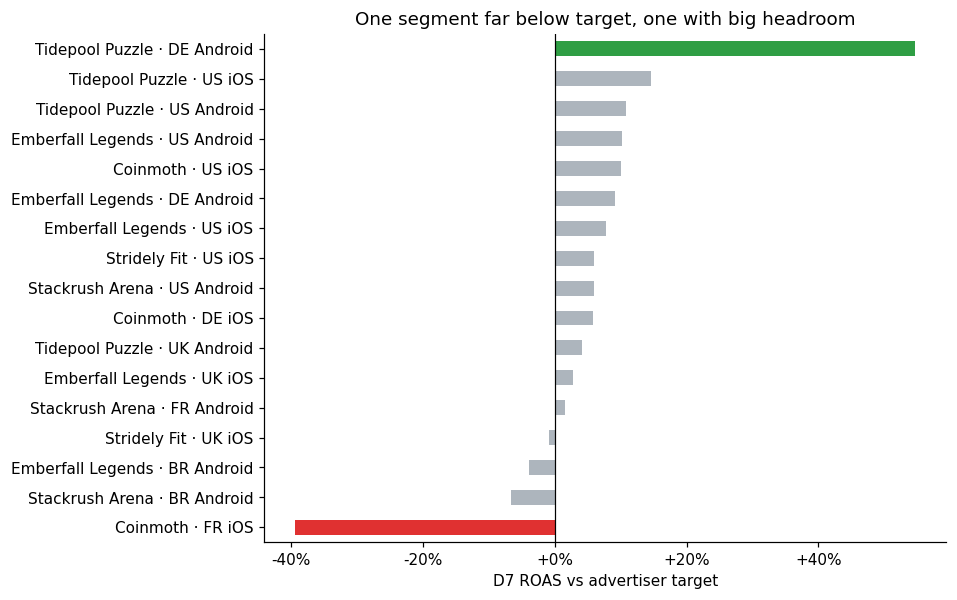

In [6]:
r2["segment"] = r2["advertiser"] + " · " + r2["geo"] + " " + r2["os"]
colors = r2["status"].map({"Below target": "#E03131", "Headroom": "#2F9E44", "On target": "#ADB5BD"})
ax = r2.plot.barh(x="segment", y="vs_target", color=colors, legend=False, figsize=(8, 6))
ax.axvline(0, color="black", linewidth=0.8)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
ax.set_xlabel("D7 ROAS vs advertiser target"); ax.set_ylabel("")
ax.set_title("One segment far below target, one with big headroom")
plt.show()

**Takeaway:** Almost all of our groups (15 of 17) are right on target. Coinmoth FR iOS is lagging behind at 0.109 instead of 0.18, while Tidepool DE Android is beating its target with 0.31 instead of 0.20. Emberfall US iOS looks fine on paper with a 0.215 average, but section 4 reveals why that average is actually misleading.

## 3. Where is budget left on the table?

In [7]:
r3 = q("""
-- Q3. Where are caps under-filling, and is there room to bid up?
-- Cap fill = spend / daily cap. A low fill with ROAS ABOVE target means
-- we are leaving the advertiser's budget unspent for no reason.
-- NEW: HAVING filters AFTER grouping (WHERE filters before).
SELECT
    d.advertiser,
    d.geo,
    d.os,
    ROUND(AVG(d.spend_eur / d.daily_cap_eur), 3)          AS avg_cap_fill,
    ROUND(AVG(d.daily_cap_eur - d.spend_eur))             AS unfilled_eur_per_day,
    ROUND(SUM(d.revenue_d7_eur) / SUM(CASE WHEN d.revenue_d7_eur IS NOT NULL
                                           THEN d.spend_eur END), 3) AS d7_roas,
    t.roas_target_d7
FROM daily AS d
JOIN targets AS t ON d.advertiser = t.advertiser
GROUP BY d.advertiser, d.geo, d.os, t.roas_target_d7
HAVING AVG(d.spend_eur / d.daily_cap_eur) < 0.80
ORDER BY unfilled_eur_per_day DESC
""")
r3

,advertiser,geo,os,avg_cap_fill,unfilled_eur_per_day,d7_roas,roas_target_d7
0,Tidepool Puzzle,DE,Android,0.554,2674.0,0.309,0.2


**Takeaway:** We are leaving about 2,674 euros a day (around 80k euros a month) on the table because Tidepool Puzzle DE Android only hits 55% of its daily cap. It earns a 0.31 return against a target of 0.20, which means we are bidding too carefully. If we lower our internal targets a bit, we can use up the full budget and still easily beat our goal.

## 4. Early warning: did any account move in the last 14 days?

In [8]:
r4 = q("""
-- Q4. Early-warning check, account level: did any account move?
-- Compares the last 14 mature days with the 14 days before.
-- (14-day windows smooth out daily noise and weekend swings.)
-- NEW: WITH ... AS (...) creates a named temporary result (a "CTE")
--      so a long query reads top to bottom in steps.
WITH mature AS (
    SELECT * FROM daily WHERE revenue_d7_eur IS NOT NULL
),
bounds AS (
    SELECT MAX(date) AS last_day FROM mature
)
SELECT
    m.advertiser,
    ROUND(SUM(CASE WHEN m.date >  b.last_day - INTERVAL 14 DAY THEN m.revenue_d7_eur END)
        / SUM(CASE WHEN m.date <= b.last_day - INTERVAL 14 DAY THEN m.revenue_d7_eur END) - 1, 3) AS revenue_change,
    ROUND(SUM(CASE WHEN m.date >  b.last_day - INTERVAL 14 DAY THEN m.installs END) * 1.0
        / SUM(CASE WHEN m.date <= b.last_day - INTERVAL 14 DAY THEN m.installs END) - 1, 3)       AS installs_change
FROM mature AS m, bounds AS b
WHERE m.date > b.last_day - INTERVAL 28 DAY
GROUP BY m.advertiser
ORDER BY revenue_change
""")
r4

,advertiser,revenue_change,installs_change
0,Emberfall Legends,-0.144,0.011
1,Tidepool Puzzle,-0.017,0.012
2,Stackrush Arena,0.000,0.001
3,Coinmoth,0.004,0.009
4,Stridely Fit,0.012,-0.001


**Takeaway:** Even though Emberfall got a few more installs (+1.1%), its 7-day revenue fell by 14.4%. Because our traffic volume is fine, this proves it is not a traffic issue.

## 5. Where exactly did it move?

In [9]:
r5 = q("""
-- Q5. Same check per segment: where exactly did it move?
WITH mature AS (
    SELECT * FROM daily WHERE revenue_d7_eur IS NOT NULL
),
bounds AS (
    SELECT MAX(date) AS last_day FROM mature
),
windows AS (
    SELECT
        m.advertiser, m.geo, m.os,
        CASE WHEN m.date > b.last_day - INTERVAL 14 DAY THEN 'recent' ELSE 'prior' END AS win,
        SUM(m.revenue_d7_eur) AS revenue,
        SUM(m.installs)       AS installs
    FROM mature AS m, bounds AS b
    WHERE m.date > b.last_day - INTERVAL 28 DAY
    GROUP BY 1, 2, 3, 4
)
SELECT
    advertiser, geo, os,
    ROUND(MAX(CASE WHEN win = 'prior' THEN revenue END))  AS rev_prior_14d,
    ROUND(MAX(CASE WHEN win = 'recent' THEN revenue END))  AS rev_recent_14d,
    ROUND(MAX(CASE WHEN win = 'recent' THEN revenue END)
        / MAX(CASE WHEN win = 'prior' THEN revenue END) - 1, 3)  AS revenue_change,
    ROUND(MAX(CASE WHEN win = 'recent' THEN installs END) * 1.0
        / MAX(CASE WHEN win = 'prior' THEN installs END) - 1, 3) AS installs_change
FROM windows
GROUP BY advertiser, geo, os
ORDER BY revenue_change
LIMIT 5
""")
r5

,advertiser,geo,os,rev_prior_14d,rev_recent_14d,revenue_change,installs_change
0,Emberfall Legends,US,iOS,69692.0,45187.0,-0.352,0.038
1,Emberfall Legends,BR,Android,6790.0,6635.0,-0.023,0.007
2,Tidepool Puzzle,DE,Android,14694.0,14371.0,-0.022,0.019
3,Tidepool Puzzle,US,iOS,21516.0,21078.0,-0.020,0.016
4,Emberfall Legends,UK,iOS,16219.0,15958.0,-0.016,0.012


**Takeaway:** Only one group caused the drop in revenue. Emberfall US iOS lost 35.2% of its revenue even with a 3.8% bump in installs. Every other group stayed nearly the same, moving by less than 2.3%.

## 6. When did it start?

In [10]:
r6 = q("""
-- Q6. Drill-down: what changed in the flagged segment?
-- One row per day for Emberfall Legends US iOS. If installs and
-- retention are steady but revenue per install falls, the users did not
-- get worse: something changed in monetisation or in measurement.
SELECT
    date,
    installs,
    ROUND(d1_retained_users * 1.0 / installs, 3)  AS d1_retention,
    ROUND(d7_retained_users * 1.0 / installs, 3)  AS d7_retention,
    ROUND(revenue_d7_eur / installs, 3)           AS d7_revenue_per_install,
    ROUND(revenue_d7_eur / spend_eur, 3)          AS d7_roas
FROM daily
WHERE advertiser = 'Emberfall Legends'
  AND geo = 'US' AND os = 'iOS'
  AND revenue_d7_eur IS NOT NULL
ORDER BY date
""")
r6

,date,installs,d1_retention,d7_retention,d7_revenue_per_install,d7_roas
0,2026-08-01,4068,0.443,0.176,1.197,0.221
1,2026-08-02,3596,0.430,0.183,1.470,0.247
2,2026-08-03,3849,0.409,0.175,1.353,0.238
3,2026-08-04,3705,0.427,0.184,1.449,0.249
4,2026-08-05,3533,0.422,0.177,1.433,0.243
5,2026-08-06,3642,0.424,0.176,1.376,0.233
6,2026-08-07,3475,0.402,0.182,1.504,0.251
7,2026-08-08,4092,0.402,0.185,1.293,0.242
8,2026-08-09,3917,0.429,0.177,1.317,0.235
9,2026-08-10,3654,0.429,0.185,1.367,0.234


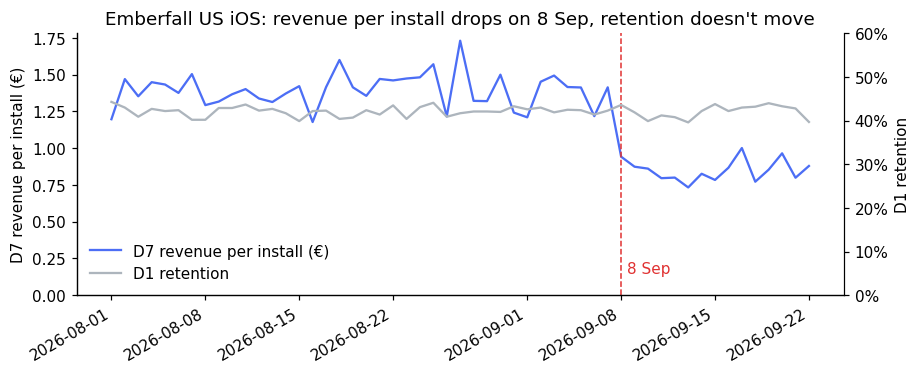

In [11]:
fig, ax1 = plt.subplots(figsize=(9, 3.5))
l1, = ax1.plot(r6["date"], r6["d7_revenue_per_install"], color="#4C6EF5", label="D7 revenue per install (€)")
ax1.set_ylabel("D7 revenue per install (€)"); ax1.set_ylim(0, None)
ax2 = ax1.twinx()
l2, = ax2.plot(r6["date"], r6["d1_retention"], color="#ADB5BD", label="D1 retention")
ax2.set_ylabel("D1 retention"); ax2.set_ylim(0, 0.6); ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax2.spines["right"].set_visible(True)
ax1.axvline(pd.Timestamp("2026-09-08"), color="#E03131", linestyle="--", linewidth=1)
ax1.annotate("8 Sep", (pd.Timestamp("2026-09-08"), 0.15), color="#E03131", xytext=(4, 0), textcoords="offset points")
ax1.set_title("Emberfall US iOS: revenue per install drops on 8 Sep, retention doesn't move")
ax1.legend([l1, l2], [l1.get_label(), l2.get_label()], loc="lower left", frameon=False)
fig.autofmt_xdate(); plt.show()

**Takeaway:** The amount of money we make per install took a drop on September 8 and stayed down. Meanwhile, user retention numbers stayed completely flat.

## 7. What changed? Before vs after

In [12]:
r7 = q("""
-- Q7. Before vs after the change, in one table (for the write-up).
SELECT
    CASE WHEN date >= DATE '2026-09-08' THEN 'From 8 Sep' ELSE 'Before 8 Sep' END AS period,
    ROUND(AVG(installs))                                    AS installs_per_day,
    ROUND(SUM(d1_retained_users) * 1.0 / SUM(installs), 3)  AS d1_retention,
    ROUND(SUM(d7_retained_users) * 1.0 / SUM(installs), 3)  AS d7_retention,
    ROUND(SUM(revenue_d7_eur) / SUM(installs), 3)           AS d7_revenue_per_install,
    ROUND(SUM(revenue_d7_eur) / SUM(spend_eur), 3)          AS d7_roas
FROM daily
WHERE advertiser = 'Emberfall Legends' AND geo = 'US' AND os = 'iOS'
  AND revenue_d7_eur IS NOT NULL
GROUP BY period
ORDER BY period
""")
r7

,period,installs_per_day,d1_retention,d7_retention,d7_revenue_per_install,d7_roas
0,Before 8 Sep,3721.0,0.421,0.179,1.390,0.241
1,From 8 Sep,3826.0,0.421,0.177,0.847,0.151


**Takeaway:** Starting September 8, revenue per download fell 39% (from 1.39 euros down to 0.85 euros), even though user retention stayed steady at 42% for Day 1 and 18% for Day 7. Since user quality did not drop, these points to a tracking bug or a change in how the app earns money. Our Day 7 ROAS is down to 0.151 against a 0.20 target, so we should flag this to the advertiser before they bring it up with us.

## 8. What does Almedia actually keep?

In [13]:
r8 = q("""
-- Q8. What does Almedia actually keep? Margin per segment.
-- The advertiser pays Almedia (spend_eur); Almedia pays its users rewards
-- (reward_cost_eur). The difference is Almedia's gross margin.
-- A segment can look big on spend but earn little for Almedia.
SELECT
    advertiser,
    geo,
    os,
    ROUND(SUM(spend_eur))                                              AS spend_eur,
    ROUND(SUM(spend_eur - reward_cost_eur))                            AS gross_margin_eur,
    ROUND(1 - SUM(reward_cost_eur) / SUM(spend_eur), 3)                AS margin_pct,
    ROUND(100 * SUM(spend_eur - reward_cost_eur)
              / SUM(SUM(spend_eur - reward_cost_eur)) OVER (), 1)      AS share_of_margin_pct
FROM daily
GROUP BY advertiser, geo, os
ORDER BY gross_margin_eur DESC
""")
r8

,advertiser,geo,os,spend_eur,gross_margin_eur,margin_pct,share_of_margin_pct
0,Emberfall Legends,US,iOS,1287516.0,491774.0,0.382,23.7
1,Emberfall Legends,US,Android,922644.0,351329.0,0.381,16.9
2,Tidepool Puzzle,US,iOS,399818.0,151744.0,0.380,7.3
3,Coinmoth,US,iOS,373897.0,142207.0,0.380,6.9
4,Emberfall Legends,UK,iOS,335960.0,128400.0,0.382,6.2
5,Tidepool Puzzle,US,Android,334514.0,127180.0,0.380,6.1
6,Emberfall Legends,DE,Android,306635.0,116692.0,0.381,5.6
7,Stackrush Arena,US,Android,289212.0,110019.0,0.380,5.3
8,Stridely Fit,US,iOS,219069.0,82771.0,0.378,4.0
9,Tidepool Puzzle,DE,Android,199589.0,80423.0,0.403,3.9


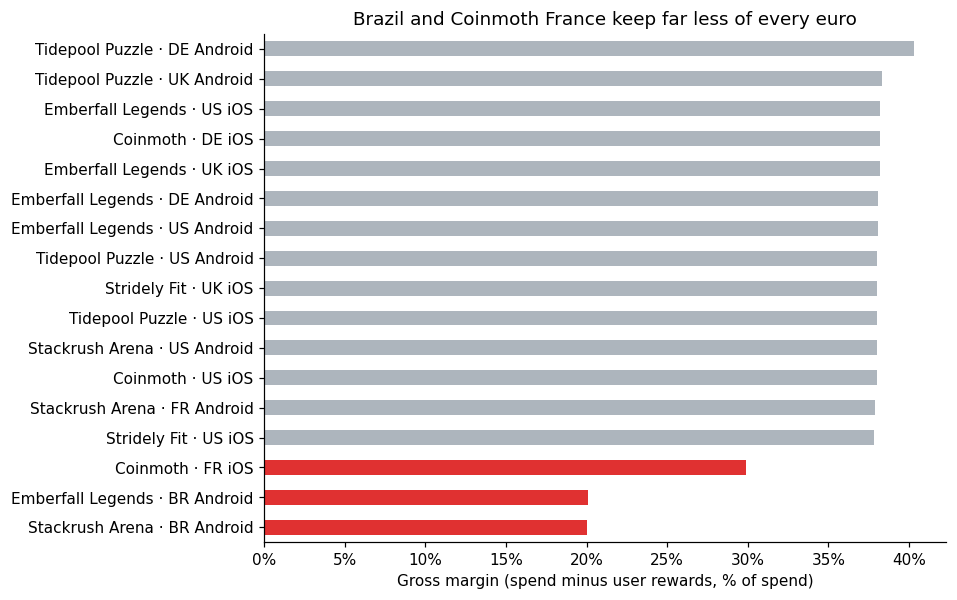

In [14]:
r8["segment"] = r8["advertiser"] + " · " + r8["geo"] + " " + r8["os"]
d = r8.sort_values("margin_pct")
colors = ["#E03131" if m < 0.32 else "#ADB5BD" for m in d["margin_pct"]]
ax = d.plot.barh(x="segment", y="margin_pct", color=colors, legend=False, figsize=(8, 6))
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Gross margin (spend minus user rewards, % of spend)"); ax.set_ylabel("")
ax.set_title("Brazil and Coinmoth France keep far less of every euro")
plt.show()

**Takeaway:** Most groups keep around 38% of ad spend after user payout costs, but Brazil keeps only 20% and Coinmoth FR iOS keeps 30%. Stackrush spends almost twice as much in Brazil as in France but earns less profit there. Since Emberfall alone brings in 54% of our total profit, fixing its revenue drop is extremely urgent.

## 9. What is each recommendation worth per month?

In [15]:
r9 = q("""
-- Q9. What is each recommendation worth per month?
-- Uses the last 28 days as the current run rate. Every assumption sits in
-- one place (the "assumptions" step) so you can change it and rerun.
-- NEW: UNION ALL stacks the results of several SELECTs into one table.
WITH assumptions AS (
    SELECT
        0.90 AS tidepool_target_fill,   -- fill Tidepool DE to 90% of its cap
        0.40 AS coinmoth_fr_cut,        -- cut Coinmoth FR volume by 40% to move ROAS toward target
        30   AS days_per_month
),
run_rate AS (
    SELECT
        advertiser, geo, os,
        AVG(spend_eur)                                   AS spend_per_day,
        AVG(daily_cap_eur)                               AS cap_per_day,
        AVG(spend_eur / daily_cap_eur)                   AS cap_fill,
        1 - SUM(reward_cost_eur) / SUM(spend_eur)        AS margin_pct
    FROM daily
    WHERE date > (SELECT MAX(date) FROM daily) - INTERVAL 28 DAY
    GROUP BY advertiser, geo, os
)
-- 1) Opportunity: fill Tidepool DE Android's cap
SELECT
    'Fill Tidepool DE Android cap' AS action,
    'Upside'                       AS type,
    ROUND((a.tidepool_target_fill - r.cap_fill) * r.cap_per_day * a.days_per_month)              AS spend_eur_per_month,
    ROUND((a.tidepool_target_fill - r.cap_fill) * r.cap_per_day * a.days_per_month * r.margin_pct) AS margin_eur_per_month
FROM run_rate AS r, assumptions AS a
WHERE r.advertiser = 'Tidepool Puzzle' AND r.geo = 'DE' AND r.os = 'Android'

UNION ALL
-- 2) Risk: Emberfall pulls US iOS budget if measured ROAS stays below target
SELECT
    'Resolve Emberfall US iOS drop', 'At risk',
    ROUND(r.spend_per_day * a.days_per_month),
    ROUND(r.spend_per_day * a.days_per_month * r.margin_pct)
FROM run_rate AS r, assumptions AS a
WHERE r.advertiser = 'Emberfall Legends' AND r.geo = 'US' AND r.os = 'iOS'

UNION ALL
-- 3) Cost: cutting Coinmoth FR iOS volume (short-term revenue Almedia gives up)
SELECT
    'Cut Coinmoth FR iOS volume', 'Cost',
    ROUND(-a.coinmoth_fr_cut * r.spend_per_day * a.days_per_month),
    ROUND(-a.coinmoth_fr_cut * r.spend_per_day * a.days_per_month * r.margin_pct)
FROM run_rate AS r, assumptions AS a
WHERE r.advertiser = 'Coinmoth' AND r.geo = 'FR' AND r.os = 'iOS'

UNION ALL
-- 4) What that cut protects: the whole Coinmoth account
SELECT
    'Coinmoth account protected by the cut', 'At risk',
    ROUND(SUM(r.spend_per_day) * MAX(a.days_per_month)),
    ROUND(SUM(r.spend_per_day * r.margin_pct) * MAX(a.days_per_month))
FROM run_rate AS r, assumptions AS a
WHERE r.advertiser = 'Coinmoth'
""")
r9

,action,type,spend_eur_per_month,margin_eur_per_month
0,Fill Tidepool DE Android cap,Upside,62474.0,25228.0
1,Resolve Emberfall US iOS drop,At risk,644813.0,244640.0
2,Cut Coinmoth FR iOS volume,Cost,-29600.0,-8834.0
3,Coinmoth account protected by the cut,At risk,344039.0,124887.0


**Takeaway:** Fixing the Emberfall US iOS revenue drop is our top priority because it protects 645,000 euros of monthly ad spend and 245,000 euros of profit. Pushing Tidepool DE Android up to 90% of its spend limit adds another 62,000 euros in spend and 25,000 euros in monthly profit. Lastly, scaling back Coinmoth FR iOS loses us 9,000 euros a month in profit, but it protects a major account worth 344,000 euros in monthly spend and 125,000 euros in profit.

## What I'd do Monday morning

1. **Emberfall US iOS (today, ~€245k monthly profit at risk)**: message the advertiser today with the data table. Ask if anything changed on 8 Sep, such as an app update, pricing, or broken revenue tracking. User retention is steady, so check tracking issues before cutting bids on our biggest account.

2. **Tidepool Puzzle DE Android (this week, ~€25k monthly profit potential)**: lower the internal target in steps over 7 to 14 days to spend more budget, stopping when the target gets close to 0. 24.

3. **Coinmoth FR iOS (this week, ~€9k monthly profit cost)**: raise the internal target to lower spend and review its reward levels, as its profit margin is thin. First ask the advertiser if French users take longer than 7 days to spend money, which happens with finance apps and makes Day 7 numbers look worse than they are.

4. **Brazil (next)**: review reward levels for the Brazil groups; with a 20% margin, every euro spent there earns Almedia half of what it earns everywhere else.

5. **Process**: run this check every day as an alert so a drop like Emberfall's gets caught on day 2 instead of week 2.